# CS4 - Making the Most of an Imperfect Well (16/7-1)

**Petrophys Case Studies - the honesty & robustness study**

---

## 1. The brief

> *"Well 16/7-1 is the only log data we have over this fault block. It is old, and it is
> incomplete: there is no neutron log, no PEF, the deep resistivity reads impossibly high
> in the tight streaks, and there are washout zones. Management still needs a defensible
> porosity and net-pay number to decide whether to carry this prospect forward. Give us the
> best interpretation you honestly can - and be explicit about which parts of it we can trust
> and which parts rest on synthetic data."*

This is the situation every petrophysicist eventually faces: a real, imperfect well and a
decision that cannot wait for a perfect dataset. The professional answer is **not** to refuse,
and it is **not** to quietly paper over the gaps. It is to:

1. **Inventory** exactly what was measured and what is missing (a *data readiness* assessment).
2. **Repair** the recoverable problems (off-scale resistivity, washout) transparently.
3. **Reconstruct** the genuinely-missing curves with a *validated* model - and prove the model
   is credible on this well before trusting it.
4. **Interpret** with the mixed measured + synthetic dataset, carrying an **uncertainty flag**
   on every interval that leans on synthetic data.
5. **Deliver** a caveated answer that a reviewer can audit line by line.

The deliverable is a **data readiness report** (measured vs imputed) plus a **caveated net-pay
result** that is honest about which parts rest on imputed data.

### How this differs from CS1-CS3
CS1 evaluated a clean discovery well; CS2 and CS3 had core control and complete log suites.
CS4 has none of that luxury. The emphasis here is entirely on **QC, imputation, validation and
uncertainty communication** - the parts of the job that separate a defensible interpretation
from a dangerous one. We reference the interpretation mechanics taught in the Part A/B tutorials
rather than re-deriving them.

## Setup

We load `petrophys`, matplotlib (inline so figures embed), and the specific QC / imputation
tools this study needs. All data is bundled with the library - no external files.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")  # silence sklearn pickle-version warnings from the model pack

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

# QC tools
from petrophys.qaqc import (
    apply_value_range_qc,
    value_range_qc_note,
    detect_washout,
)
# ML curve imputation
from petrophys.imputation import (
    PretrainedCurveImputer,
    default_pretrained_model_path,
)
# Interpretation
from petrophys.clay_volume import vcl_from_gr
from petrophys.petrophysics.porosity import density_porosity, nd_weighted_porosity, effective_porosity
from petrophys.petrophysics.saturation import archie

print("petrophys", petrophys.__version__)
print("geolink sample wells:", petrophys.list_samples("geolink"))

petrophys 0.1.0
geolink sample wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


## 2. The well & data - a first look

**16/7-1** is a Geolink North Sea well logged in metres. Let us load it and see exactly what
curves survived digitisation.

In [2]:
well = read_las(petrophys.sample("16_7-1"))

print("Well name    :", well.name)
print("Depth unit   :", well.depth_unit)
print("Interval     : %.1f - %.1f %s" % (well.start_depth, well.stop_depth, well.depth_unit))
print("Sample step  : %.4f %s" % (well.step, well.depth_unit))
print("N samples    :", well.n_samples)
print("N curves     :", well.n_curves)
print()
print("Curves present:")
for c in well.curves:
    print("  -", c)

Well name    : 16/7-1
Depth unit   : m
Interval     : 367.9 - 2651.7 m
Sample step  : 0.1524 m
N samples    : 14986
N curves     : 12

Curves present:
  - LITHOLOGY_GEOLINK
  - DCAL
  - CALI
  - BS
  - DRHO
  - RHOB
  - GR
  - DTC
  - RDEP
  - SP
  - RSHA
  - RMED


Twelve curves. Two things jump out immediately for anyone who has done a formation
evaluation:

- There is a **GR, RHOB, DTC (sonic), SP and a full resistivity suite (RDEP/RMED/RSHA)** - a
  workable backbone.
- There is **no NPHI (neutron)** and **no PEF**. The neutron-density crossplot - the workhorse
  for porosity and gas detection - is off the table until we do something about it.
- There is a **CALI, BS and DCAL** (differential caliper), which is exactly what we need to
  find washout.

Before trusting any of it, we quantify *how complete* each curve actually is.

## 3. Workflow plan

The order below is deliberate - each step de-risks the next:

| # | Step | Why here |
|---|------|----------|
| 1 | **Data readiness**: null coverage per curve, detect missing NPHI/PEF | Know the gaps before touching the data |
| 2 | **Off-scale RDEP**: detect, flag, clip via `value_range_qc` | Bad resistivity corrupts *both* Sw and the ML features - fix first |
| 3 | **Washout**: `detect_washout` via CALI-BS / DRHO | Flag intervals where RHOB (and thus porosity) is unreliable |
| 4 | **Validate the imputer**: blank-and-restore on a *present* curve (RHOB) | Never trust a synthetic curve you have not error-checked on real data |
| 5 | **Impute the missing curve**: synthesise NPHI with the pretrained model | Recover the neutron so we can do a proper N-D porosity |
| 6 | **Interpret**: Vcl -> porosity -> Archie Sw on measured + imputed curves | The actual evaluation |
| 7 | **Net pay with uncertainty flags** | The caveated deliverable |

The golden rule threaded through all of it: **anything derived from a synthetic curve inherits
the synthetic curve's uncertainty**, and we track that explicitly.

## 4. Execution

### 4.1 Data readiness - null coverage per curve

A curve can be *present* in the LAS header but still be 90% null. We compute, for every curve,
the valid-sample fraction and flag the ones that are effectively unusable. We also make the
missing curves (NPHI, PEF) explicit against the standard geolink target list.

In [3]:
# Curves the pretrained geolink imputer knows about (its target list) - our "expected" suite
imputer_preview = PretrainedCurveImputer.from_pretrained()
EXPECTED = imputer_preview.target_curves + ["DCAL"]  # DCAL is a QC curve, not an imputer target
EXPECTED = sorted(set(EXPECTED))

rows = []
for c in EXPECTED:
    if well.has_curve(c):
        cu = well.get(c)
        valid = cu.valid_count()
        cov = 100.0 * valid / well.n_samples
        rows.append({
            "curve": c, "status": "present",
            "valid": valid, "null": cu.null_count(),
            "coverage_%": round(cov, 1),
            "min": round(float(np.nanmin(cu.data)), 3) if valid else np.nan,
            "max": round(float(np.nanmax(cu.data)), 3) if valid else np.nan,
        })
    else:
        rows.append({"curve": c, "status": "MISSING", "valid": 0, "null": well.n_samples,
                     "coverage_%": 0.0, "min": np.nan, "max": np.nan})

readiness = pd.DataFrame(rows).sort_values("coverage_%").reset_index(drop=True)
print(readiness.to_string(index=False))

curve  status  valid  null  coverage_%       min      max
 NPHI MISSING      0 14986         0.0       NaN      NaN
  PEF MISSING      0 14986         0.0       NaN      NaN
 RMED present   7101  7885        47.4    -0.013    2.356
 DRHO present   7980  7006        53.2    -0.066    0.089
 RHOB present   7980  7006        53.2     1.732    2.961
  DTC present   9427  5559        62.9    14.896   56.205
 RDEP present  14777   209        98.6    -0.023 4858.222
   GR present  14871   115        99.2     1.225  117.510
 RSHA present  14938    48        99.7     0.059   65.879
 CALI present  14986     0       100.0     5.701   21.995
 DCAL present  14986     0       100.0    -6.496   12.036
   BS present  14986     0       100.0     8.500   17.500
   SP present  14985     1       100.0 -6183.089   96.838


Reading the table top-to-bottom:

- **NPHI and PEF: MISSING** (0% coverage) - genuinely absent, candidates for imputation.
- **RMED, DTC, RHOB, DRHO: ~47-63% coverage** - these were only recorded over part of the
  hole. RHOB/DRHO share the same null pattern (same density tool run).
- **CALI, BS, DCAL, GR: near-100%** - our reliable backbone and QC curves.
- **RDEP max = 4860 ohm.m** - physically implausible for a water-bearing clastic; this is the
  off-scale problem the brief warned about (a good deep resistivity in tight streaks caps out).

Let us visualise the readiness as a bar chart - our first deliverable figure.

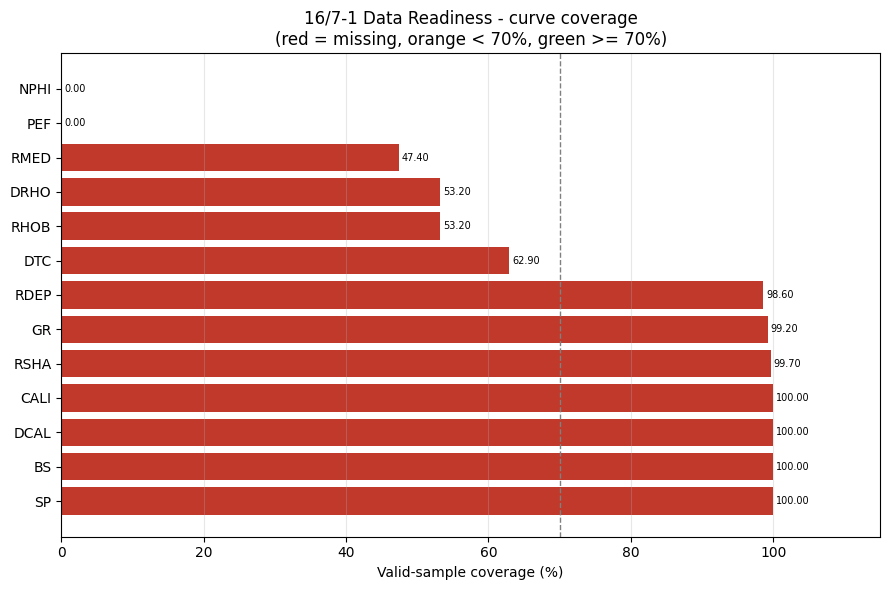

Missing curves : 2
Partial (<70%) : 4


In [4]:
from petrophys.visualization import create_bar_comparison

# First deliverable figure: curve-coverage bar chart via the library bar helper.
# Order the bars by coverage (ascending) so missing/partial curves surface at top.
rd = readiness.sort_values("coverage_%").reset_index(drop=True)
colors = []
for _, r in rd.iterrows():
    if r["status"] == "MISSING":
        colors.append("#c0392b")       # red - missing
    elif r["coverage_%"] < 70:
        colors.append("#e67e22")       # orange - partial
    else:
        colors.append("#27ae60")       # green - good

fig, ax = create_bar_comparison(
    rd["curve"].tolist(), rd["coverage_%"].values,
    horizontal=True, colors=colors, value_labels=True, figsize=(9, 6),
    xlabel="Valid-sample coverage (%)",
    title="16/7-1 Data Readiness - curve coverage\n(red = missing, orange < 70%, green >= 70%)",
)
ax.set_xlim(0, 115)
ax.axvline(70, ls="--", color="grey", lw=1)
plt.tight_layout()
plt.show()

n_missing = int((readiness["status"] == "MISSING").sum())
n_partial = int(((readiness["status"] == "present") & (readiness["coverage_%"] < 70)).sum())
print("Missing curves :", n_missing)
print("Partial (<70%) :", n_partial)

### 4.2 Off-scale deep resistivity (RDEP) - detect, flag, clip

**Why this matters.** Archie's equation gives $S_w \propto \sqrt{R_w / (R_t\,\phi^m)}$. If $R_t$
(the deep resistivity) reads 4860 ohm.m when the true formation resistivity is, say, 40 ohm.m
because the tool railed in a tight carbonate streak, Archie returns an **artificially low $S_w$**
- it will paint a wet zone as pay. Off-scale resistivity is one of the classic ways to
manufacture a phantom hydrocarbon column. It must be caught before saturation.

`petrophys.qaqc.value_range_qc` carries a physically-motivated cap for each curve family. For
RDEP/RT the cap is **0.01-2000 ohm.m**; finite values outside that are set to NaN (flagged as
untrustworthy rather than silently kept).

We capture a *before* copy of RDEP, apply the QC, then show the difference.

In [5]:
rdep_before = well.get("RDEP").data.copy()

# Apply value-range QC to the resistivity + SP curves (returns a per-curve report)
qc_report = apply_value_range_qc(well, ["RDEP", "RMED", "RSHA", "SP", "GR", "RHOB"])
rdep_after = well.get("RDEP").data.copy()

# summarise what changed
for item in qc_report:
    if item["changed"]:
        print("%-6s cap [%.2f, %.1f]  set-NaN=%d  (below=%d, above=%d)"
              % (item["curve"], item["low"], item["high"],
                 item["changed"], item["below"], item["above"]))

print()
print("RDEP off-scale (flagged) samples :", int(np.sum(np.isfinite(rdep_before) & np.isnan(rdep_after))))
print("RDEP max before :", round(float(np.nanmax(rdep_before)), 1), "ohm.m")
print("RDEP max after  :", round(float(np.nanmax(rdep_after)), 1), "ohm.m")
print()
print(value_range_qc_note(qc_report))

RDEP   cap [0.01, 2000.0]  set-NaN=2954  (below=4, above=2950)
RMED   cap [0.01, 2000.0]  set-NaN=3  (below=3, above=0)

RDEP off-scale (flagged) samples : 2954
RDEP max before : 4858.2 ohm.m
RDEP max after  : 1997.0 ohm.m

VALUE RANGE QC: finite values outside configured ranges were set to NaN; SW/SWA and SXO/SWXO/SWXOA were clipped to 0-1. Changed: RDEP set NaN=2954 (<0.01:4, >2000.0:2950); RMED set NaN=3 (<0.01:3, >2000.0:0).


Nearly **3000 RDEP samples** were reading above 2000 ohm.m and have been flagged out. Note
the QC also caught a handful of near-zero (negative) resistivities. Let us plot the deep
resistivity before and after on a log scale so the off-scale spikes are visible.

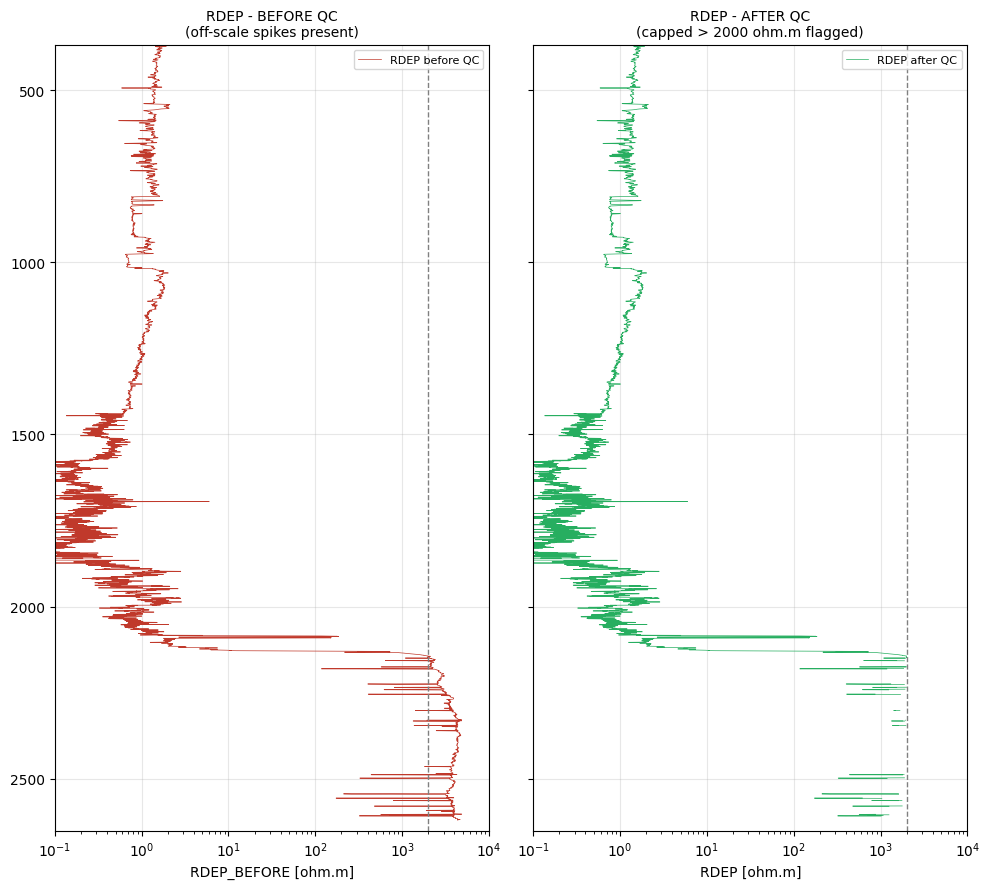

The red spikes to the right of the dashed line in the BEFORE panel are gone in AFTER;
those depths now carry NaN in RDEP and will be excluded from Sw rather than faked.


In [6]:
from petrophys.visualization import LogPlot

# Attach the pre-QC RDEP so the library LogPlot can render before vs after on a
# shared depth axis. (RDEP on the well is already the QC'd / capped version.)
well.add_curve("RDEP_BEFORE", rdep_before, unit="ohm.m",
               description="Deep resistivity before value-range QC (off-scale spikes)")

lp = LogPlot(well, figsize=(10, 9))
lp.create_figure(n_tracks=2)
lp.add_curve(0, "RDEP_BEFORE", color="#c0392b", log_scale=True, xlim=(0.1, 1e4),
             label="RDEP before QC")
lp.axes[0].axvline(2000, ls="--", color="grey", lw=1)
lp.axes[0].set_title("RDEP - BEFORE QC\n(off-scale spikes present)", fontsize=10)
lp.add_curve(1, "RDEP", color="#27ae60", log_scale=True, xlim=(0.1, 1e4),
             label="RDEP after QC")
lp.axes[1].axvline(2000, ls="--", color="grey", lw=1)
lp.axes[1].set_title("RDEP - AFTER QC\n(capped > 2000 ohm.m flagged)", fontsize=10)
lp.set_depth_range()
lp.show()
print("The red spikes to the right of the dashed line in the BEFORE panel are gone in AFTER;")
print("those depths now carry NaN in RDEP and will be excluded from Sw rather than faked.")

### 4.3 Washout / bad-hole detection

Density (RHOB) is a pad tool - in a washed-out hole the pad loses contact and RHOB reads too
low, inflating density porosity. `detect_washout` flags bad hole from **CALI - BS** (borehole
enlarged beyond bit size) and **|DRHO|** (large density correction). We will use these flags to
caveat porosity later.

In [7]:
wr = detect_washout(well)   # uses CALI, BS, DRHO automatically

stats = wr.statistics
depth_step = abs(well.step)
print("Washout    : %5.1f %% of hole  (%.1f m)"
      % (stats["washout_percent"], stats["washout_count"] * depth_step))
print("Large hole : %5.1f %%"          % stats["large_hole_percent"])
print("Bad hole   : %5.1f %% of hole  (%.1f m)"
      % (stats["bad_hole_percent"], stats["bad_hole_count"] * depth_step))
print()
print("Longest washout intervals (top, bottom) in m:")
long_iv = sorted(wr.washout_intervals, key=lambda t: t[1] - t[0], reverse=True)[:5]
for top, bot in long_iv:
    print("   %8.1f - %8.1f   (%.1f m)" % (top, bot, bot - top))

bad_hole_flag = wr.bad_hole_flag

Washout    :  26.2 % of hole  (597.4 m)
Large hole :   0.0 %
Bad hole   :  26.2 % of hole  (597.4 m)

Longest washout intervals (top, bottom) in m:
     2016.3 -   2083.4   (67.1 m)
     2129.2 -   2174.2   (45.0 m)
     2181.2 -   2224.5   (43.3 m)
     1579.5 -   1609.7   (30.2 m)
     1461.7 -   1490.4   (28.7 m)


The bad-hole flag marks the intervals where we will treat RHOB-derived porosity with
suspicion. We now have three QC layers registered: **missing curves**, **off-scale resistivity
(flagged)**, and **washout (flagged)**. Time to recover the missing neutron.

### 4.4 Validating the imputer BEFORE we trust it

We will use `PretrainedCurveImputer` - a pretrained model pack (XGBoost / random-forest / kNN)
trained on the wider Geolink dataset - to synthesise the missing NPHI from the curves 16/7-1
*does* have. But there is a trap: **there is no NPHI ground truth in this well**, so we cannot
directly check the synthetic NPHI's accuracy.

The professional workaround is a **blank-and-restore test**: take a curve that *is* present and
trusted (here **RHOB** over its measured interval), artificially null it out over a test block,
ask the imputer to reconstruct it from the same companion curves it would use for NPHI, and
compare the reconstruction against the truth we hid. If the model reproduces a real curve well,
we gain justified confidence in its synthetic curve - and we quantify the error we should carry.

First, inspect the model pack.

In [8]:
imputer = PretrainedCurveImputer.from_pretrained()
print("Model pack path :", default_pretrained_model_path().name)
print("Algorithms      :", imputer.model_names)
print("Target curves   :", imputer.target_curves)
print()
# What does the imputer need to predict NPHI, and do we have those features?
nphi_entry = imputer.model_pack["models"]["xgboost"]["NPHI"]
nphi_features = nphi_entry["features"] if isinstance(nphi_entry, dict) else []
print("Features the XGBoost NPHI model expects:")
print("  ", nphi_features)
present = [f for f in nphi_features if well.has_curve(f)]
absent  = [f for f in nphi_features if not well.has_curve(f)]
print("Present in 16/7-1 :", present)
print("Absent  in 16/7-1 :", absent, "(model handles missing features gracefully)")

Model pack path : geolink_curve_imputation.joblib
Algorithms      : ['knn', 'rf', 'xgboost']
Target curves   : ['BS', 'CALI', 'DRHO', 'DTC', 'GR', 'NPHI', 'PEF', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SP']

Features the XGBoost NPHI model expects:
   ['BS', 'CALI', 'DRHO', 'DTC', 'DTS', 'GR', 'PEF', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'RXO', 'SP']
Present in 16/7-1 : ['BS', 'CALI', 'DRHO', 'DTC', 'GR', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SP']
Absent  in 16/7-1 : ['DTS', 'PEF', 'RXO'] (model handles missing features gracefully)


The imputer needs at least 2 companion curves per sample (`min_available_features=2`) and
gracefully ignores features the well lacks (DTS, RXO, PEF here). We have 9-10 usable feature
curves, which is ample.

**Important design point about the API:** `impute_missing` only *fills nulls in an existing
curve* - it raises `KeyError` if the target curve is absent. So to synthesise a genuinely-missing
curve we must first add an all-NaN placeholder curve, then impute it. We use exactly that pattern
for NPHI in the next section. For the validation here, RHOB already exists, so we just blank part
of it.

Now run the blank-and-restore on RHOB using the **xgboost** model.

In [9]:
import copy

# Work on a copy so we never corrupt the real well
val_well = copy.deepcopy(well)
rhob_truth = val_well.get("RHOB").data.copy()

# Choose a test block INSIDE the measured RHOB interval (so we have truth to compare against)
valid_idx = np.where(np.isfinite(rhob_truth))[0]
BLOCK = 500
start = valid_idx[len(valid_idx) // 2]                 # middle of the measured section
test_idx = valid_idx[(valid_idx >= start) & (valid_idx < start + BLOCK)]
test_mask = np.zeros(val_well.n_samples, dtype=bool)
test_mask[test_idx] = True

# Blank the test block
d = val_well.get("RHOB").data.copy()
d[test_mask] = np.nan
val_well.get("RHOB").data = d

top_m, bot_m = float(well.depth[test_idx[0]]), float(well.depth[test_idx[-1]])
print("Blanked RHOB test block : %.1f - %.1f m  (%d samples)" % (top_m, bot_m, test_mask.sum()))

# Impute the blanked RHOB
res_val = imputer.impute_missing(val_well, "RHOB", model_name="xgboost", inplace=True)
rhob_pred = val_well.get("RHOB").data

# Error stats over ONLY the blanked block where we have hidden truth
both = test_mask & np.isfinite(rhob_truth) & np.isfinite(rhob_pred)
err = rhob_pred[both] - rhob_truth[both]
mae  = float(np.mean(np.abs(err)))
rmse = float(np.sqrt(np.mean(err ** 2)))
bias = float(np.mean(err))
# correlation
r = float(np.corrcoef(rhob_truth[both], rhob_pred[both])[0, 1])

print()
print("Blank-and-restore error on hidden RHOB truth (n=%d):" % both.sum())
print("   MAE   = %.4f g/cm3" % mae)
print("   RMSE  = %.4f g/cm3" % rmse)
print("   Bias  = %+.4f g/cm3" % bias)
print("   Corr  = %.3f" % r)

Blanked RHOB test block : 2036.9 - 2112.9 m  (500 samples)

Blank-and-restore error on hidden RHOB truth (n=500):
   MAE   = 0.1124 g/cm3
   RMSE  = 0.1532 g/cm3
   Bias  = -0.0743 g/cm3
   Corr  = 0.746


Interpretation of the error: an **RMSE of ~0.16 g/cm3** on RHOB (which ranges ~1.7-3.0
g/cm3) is a moderate but real error - it translates into roughly a $\pm$0.05-0.10 v/v porosity
uncertainty. The imputer captures the *trend* (positive correlation) but should **not** be
treated as a substitute for a real log. That is the honest calibration: good enough to inform,
not good enough to book reserves on alone. We visualise the restore.

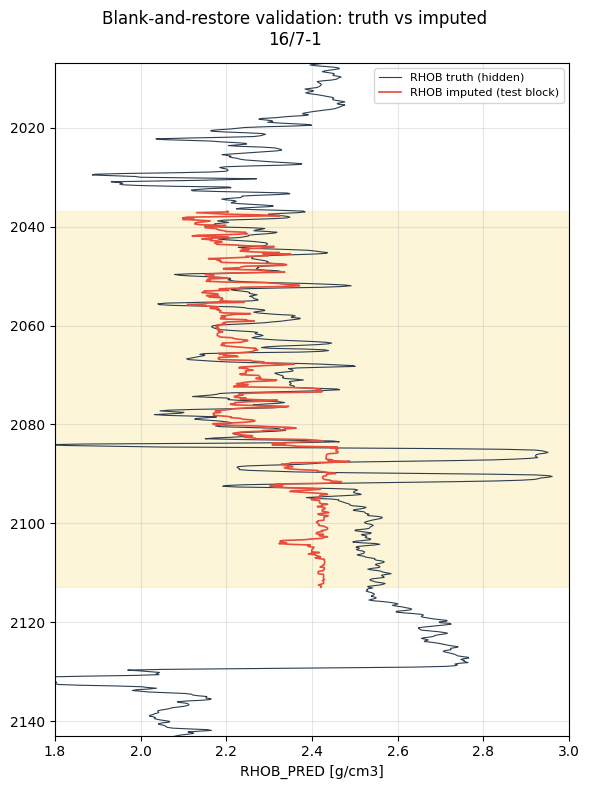

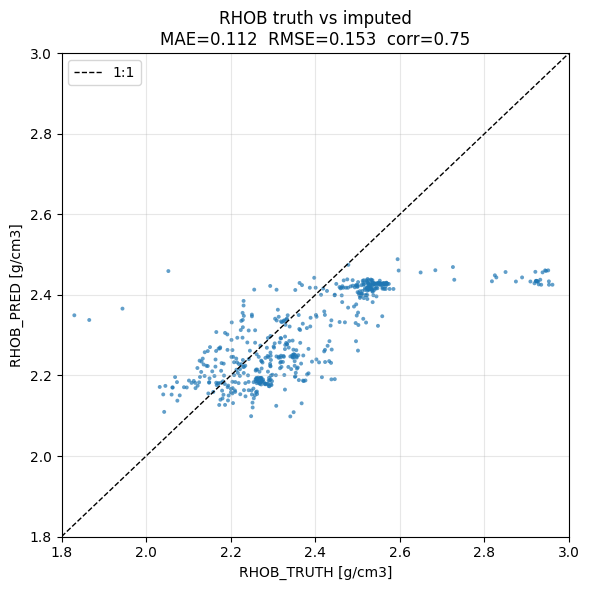

In [10]:
from petrophys.visualization import LogPlot, create_crossplot

# Attach the hidden truth and the imputed reconstruction to the validation well so
# the library plotters can render them. RHOB_PRED shows only the test block.
val_well.add_curve("RHOB_TRUTH", rhob_truth, unit="g/cm3", description="RHOB hidden truth")
val_well.add_curve("RHOB_PRED", np.where(test_mask, rhob_pred, np.nan), unit="g/cm3",
                   description="RHOB imputed over the blank-restore block")

# Panel A: blank-and-restore overlay (truth vs imputed) via the library LogPlot.
lp = LogPlot(val_well, figsize=(6, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "RHOB_TRUTH", color="#2c3e50", linewidth=0.8, xlim=(1.8, 3.0),
             label="RHOB truth (hidden)")
lp.add_curve(0, "RHOB_PRED", color="#e74c3c", linewidth=1.2, xlim=(1.8, 3.0),
             label="RHOB imputed (test block)")
lp.axes[0].axhspan(top_m, bot_m, color="#f9e79f", alpha=0.4)
lp.set_depth_range(top_m - 30, bot_m + 30)
lp.add_title("Blank-and-restore validation: truth vs imputed")
lp.show()

# Panel B: identity crossplot of truth vs imputed over the test block via the
# library crossplot, with a 1:1 identity line.
cp = create_crossplot(
    val_well, "RHOB_TRUTH", "RHOB_PRED", depth_range=(top_m, bot_m),
    xlim=(1.8, 3.0), ylim=(1.8, 3.0), marker_size=8, figsize=(6, 6),
    title="RHOB truth vs imputed\nMAE=%.3f  RMSE=%.3f  corr=%.2f" % (mae, rmse, r),
)
cp.add_line([1.8, 3.0], [1.8, 3.0], color="black", linestyle="--", label="1:1")
cp.show()

### 4.5 Imputing the genuinely-missing curve (NPHI)

Now we apply the *validated* imputer to the real problem: synthesising the absent neutron log.
Following the API pattern above, we add an all-NaN `NPHI` placeholder to the well, then let the
imputer fill it from the present companion curves.

We keep a permanent record of **which depths carry imputed NPHI** so downstream results can be
flagged.

In [11]:
# Add an empty NPHI curve so the imputer has a target to fill
if not well.has_curve("NPHI"):
    well.add_curve("NPHI", np.full(well.n_samples, np.nan),
                   unit="v/v", description="Neutron porosity (ML-imputed - synthetic)")

res_nphi = imputer.impute_missing(well, "NPHI", model_name="xgboost", inplace=True)

nphi = well.get("NPHI").data
# Depths where NPHI is synthetic (all of them here, since NPHI was 100% missing)
nphi_imputed_mask = np.isfinite(nphi)   # every filled sample is synthetic

print("NPHI imputation summary")
print("  model          :", res_nphi.model_name)
print("  features used  :", res_nphi.features_used)
print("  samples imputed:", res_nphi.imputed_count)
print("  NPHI range     : %.3f - %.3f v/v" % (np.nanmin(nphi), np.nanmax(nphi)))
print("  synthetic frac : %.1f %% of the well" % (100.0 * nphi_imputed_mask.mean()))
print()
print("  ==> EVERY NPHI sample in this well is synthetic. Any porosity or Sw that uses")
print("      NPHI is therefore model-derived and must be flagged as uncertain.")

NPHI imputation summary
  model          : xgboost
  features used  : ['BS', 'CALI', 'DRHO', 'DTC', 'GR', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SP']
  samples imputed: 14986
  NPHI range     : 0.063 - 0.414 v/v
  synthetic frac : 100.0 % of the well

  ==> EVERY NPHI sample in this well is synthetic. Any porosity or Sw that uses
      NPHI is therefore model-derived and must be flagged as uncertain.


The synthetic NPHI spans a geologically plausible **0.06-0.41 v/v**, and it inherits the
~0.16 g/cm3-equivalent uncertainty we measured on RHOB in the blank-restore. Crucially, **100%
of NPHI is synthetic** - so any neutron-density porosity is only as good as the model.

That is a strong reason to lean on the **measured RHOB** for our primary porosity and use the
synthetic NPHI as a *supporting* estimate, distinguishing the two.

### 4.6 Interpretation on the mixed (measured + imputed) dataset

With QC done and NPHI recovered, we run a standard clastic evaluation, referencing the tutorial
mechanics (see Part A porosity / saturation notebooks):

1. **Vcl** from GR (linear) - GR is fully measured, so Vcl is trustworthy everywhere.
2. **Density porosity** $\phi_D$ from measured RHOB (matrix 2.65, fluid 1.0).
3. **Neutron-density porosity** $\phi_{ND}$ from measured RHOB + **imputed** NPHI - flagged.
4. **Effective porosity** $\phi_e$ from $\phi_D$ with the Vcl shale correction (our primary
   PHIE, resting on *measured* density).
5. **Archie $S_w$** using the QC'd RDEP, with **assumed** $R_w$ (flagged - no formation-water
   sample), $a{=}1$, $m{=}n{=}2$.

We flag every assumption inline.

In [12]:
ASSUMED_RW = 0.05      # ohm.m at formation temperature - ASSUMED (no water sample) - FLAG
A, M, N = 1.0, 2.0, 2.0 # standard clastic Archie exponents - ASSUMED - FLAG

gr   = well.get("GR").data
rhob = well.get("RHOB").data
rdep = well.get("RDEP").data          # already QC'd (off-scale -> NaN)

# 1) Vcl from GR (percentiles as clean/shale baselines)
gr_clean = float(np.nanpercentile(gr, 5))
gr_shale = float(np.nanpercentile(gr, 95))
vcl = np.clip(vcl_from_gr(gr, gr_clean, gr_shale, method="linear"), 0, 1)

# 2) Density porosity from MEASURED RHOB
phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phid = np.clip(phid, 0, 0.5)

# 3) Neutron-density porosity using MEASURED RHOB + IMPUTED NPHI (supporting only)
phind = nd_weighted_porosity(nphi, phid)
phind = np.clip(phind, 0, 0.5)

# 4) Effective porosity from density (primary), shale-corrected
phie = effective_porosity(phid, vcl, phi_clay=0.15)
phie = np.clip(phie, 0, 0.5)

# 5) Archie Sw on QC'd deep resistivity
with np.errstate(invalid="ignore", divide="ignore"):
    sw = archie(rdep, ASSUMED_RW, phie, a=A, m=M, n=N)
sw = np.clip(sw, 0, 1)

print("GR clean/shale baselines : %.1f / %.1f gAPI" % (gr_clean, gr_shale))
print("PHID  (density)  mean    : %.3f v/v" % np.nanmean(phid))
print("PHIND (N-D, uses imputed): %.3f v/v" % np.nanmean(phind))
print("PHIE  (effective)  mean  : %.3f v/v" % np.nanmean(phie))
print("Sw (Archie) mean         : %.3f v/v" % np.nanmean(sw))
print()
print("ASSUMPTIONS FLAGGED: Rw=%.3f ohm.m (assumed), a=%.1f m=%.1f n=%.1f (assumed)"
      % (ASSUMED_RW, A, M, N))

GR clean/shale baselines : 3.7 / 98.2 gAPI
PHID  (density)  mean    : 0.298 v/v
PHIND (N-D, uses imputed): 0.278 v/v
PHIE  (effective)  mean  : 0.261 v/v
Sw (Archie) mean         : 0.947 v/v

ASSUMPTIONS FLAGGED: Rw=0.050 ohm.m (assumed), a=1.0 m=2.0 n=2.0 (assumed)


### 4.7 Net pay - with explicit uncertainty flags

We apply standard cutoffs and, critically, split the result into **firm** vs **uncertain** net
pay. An interval is **uncertain** if it is:
- in a **washout** zone (RHOB, hence porosity, suspect), OR
- at a depth where **RDEP was flagged off-scale** (Sw suspect), OR
- where the porosity call leans on the **imputed NPHI** rather than measured density.

Because RHOB is only measured over part of the hole, intervals *outside* the measured-density
section rely entirely on the imputed neutron - those are our clearest "uncertain" pay.

In [13]:
VCL_CUT, PHIE_CUT, SW_CUT = 0.40, 0.10, 0.60   # clastic screening cutoffs

# Base reservoir + pay test
reservoir = (vcl <= VCL_CUT) & (phie >= PHIE_CUT)
pay = reservoir & (sw <= SW_CUT)

# Uncertainty drivers
rdep_flagged = np.isfinite(rdep_before) & np.isnan(rdep)        # off-scale RDEP depths
rhob_measured = np.isfinite(rhob)                              # depths with real density
uncertain = pay & (bad_hole_flag | rdep_flagged | (~rhob_measured))
firm      = pay & ~uncertain

thick = abs(well.step)
gross = np.isfinite(gr).sum() * thick
def m(mask): return float(mask.sum() * thick)

print("Net-pay summary (cutoffs: Vcl<=%.2f, PHIE>=%.2f, Sw<=%.2f)"
      % (VCL_CUT, PHIE_CUT, SW_CUT))
print("  Gross logged interval : %8.1f m" % gross)
print("  Reservoir (rock)      : %8.1f m" % m(reservoir))
print("  Total net pay         : %8.1f m" % m(pay))
print("     - FIRM  net pay    : %8.1f m  (measured density + valid RDEP + in-gauge hole)" % m(firm))
print("     - UNCERTAIN net pay: %8.1f m  (imputed / washout / off-scale RDEP)" % m(uncertain))
frac_uncertain = 100.0 * m(uncertain) / max(m(pay), 1e-9)
print("  Uncertain fraction    : %8.1f %% of net pay" % frac_uncertain)

Net-pay summary (cutoffs: Vcl<=0.40, PHIE>=0.10, Sw<=0.60)
  Gross logged interval :   2266.3 m
  Reservoir (rock)      :    738.7 m
  Total net pay         :     33.4 m
     - FIRM  net pay    :     10.1 m  (measured density + valid RDEP + in-gauge hole)
     - UNCERTAIN net pay:     23.3 m  (imputed / washout / off-scale RDEP)
  Uncertain fraction    :     69.9 % of net pay


## 5. Integrated result - the interpretation plot

The summary figure below is the heart of the deliverable. It is a multi-track composite that
**visually distinguishes measured from imputed / flagged data** so a reviewer can see at a glance
where the answer is firm and where it rests on synthesis:

- **Track 1** - GR (measured, trustworthy) + washout shading.
- **Track 2** - RHOB (measured, shaded where it exists) and the **imputed NPHI** in a distinct
  colour, so the synthetic curve is never mistaken for a log.
- **Track 3** - deep resistivity, with off-scale-flagged depths marked.
- **Track 4** - PHIE and Sw.
- **Track 5** - the net-pay flag, split **firm (green)** vs **uncertain (hatched orange)**.

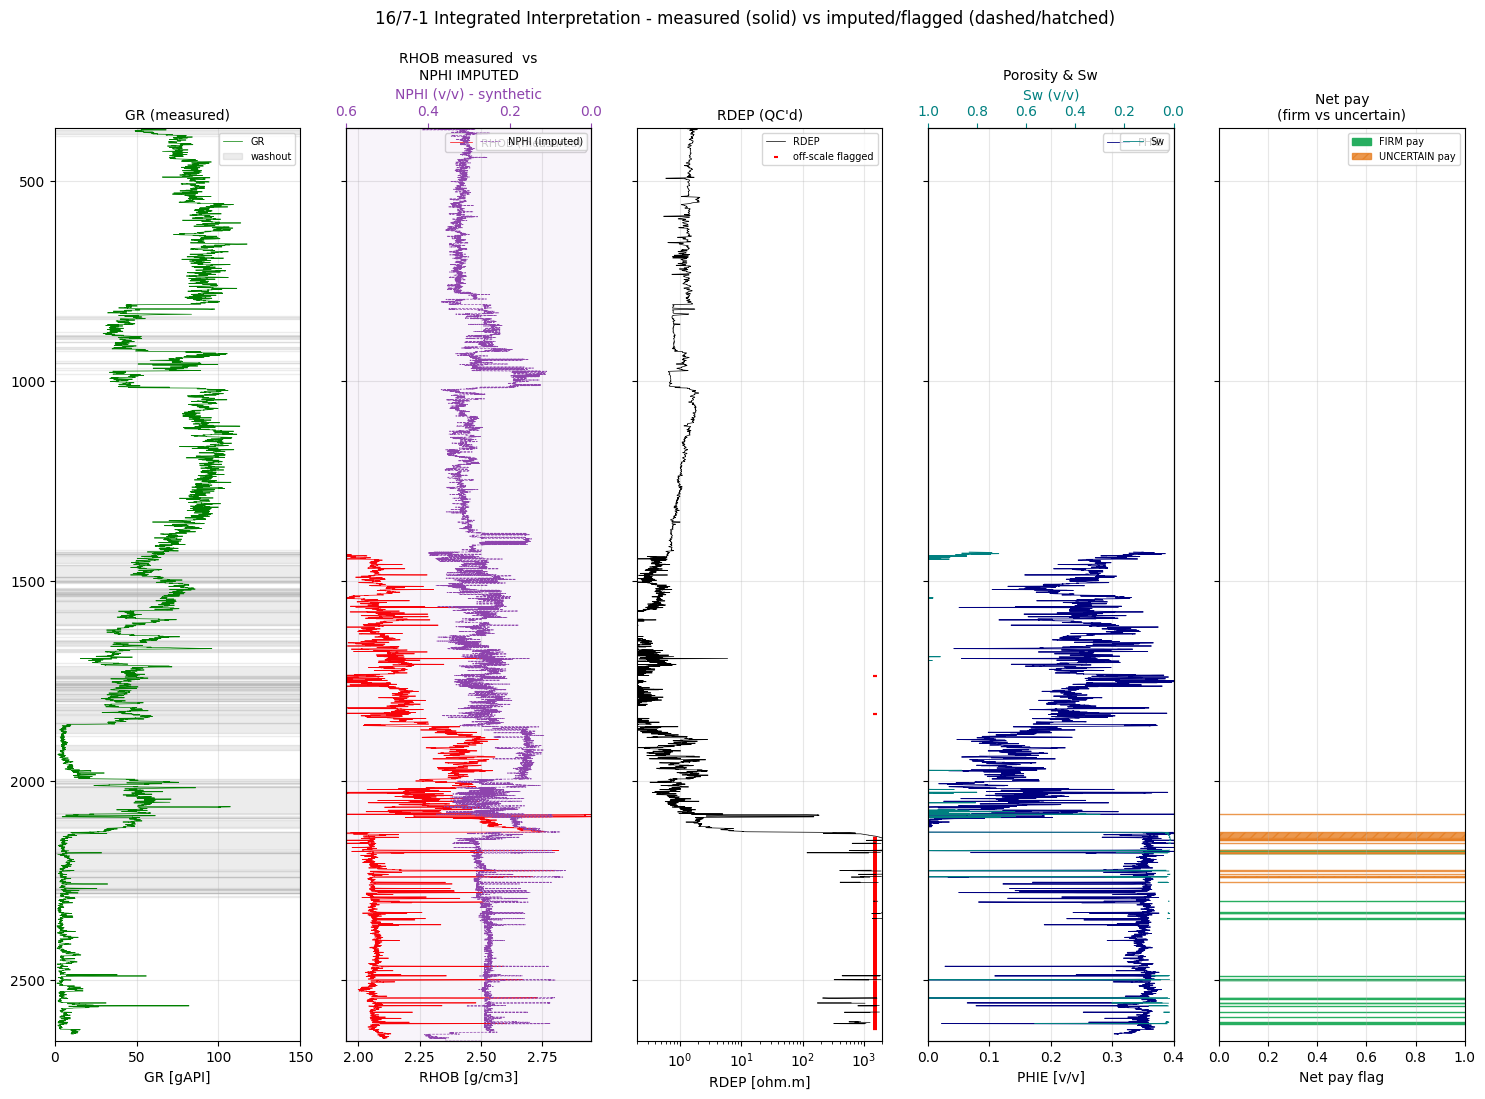

In [14]:
from petrophys.visualization import LogPlot

# Attach the interpretation curves and the firm/uncertain pay flags so the library
# LogPlot renders the whole composite (measured curves solid, imputed NPHI dashed
# in a distinct colour, net pay split firm vs uncertain).
well.add_curve("VCL", vcl, unit="v/v")
well.add_curve("PHIE", phie, unit="v/v")
well.add_curve("SW", sw, unit="v/v")
well.add_curve("NET_PAY_FIRM", firm.astype(float), unit="")
well.add_curve("NET_PAY_UNCERTAIN", uncertain.astype(float), unit="")

lp = LogPlot(well, figsize=(15, 11))
lp.create_figure(n_tracks=5)

# Track 1: GR (measured) + washout shading
lp.add_curve(0, "GR", color="green", xlim=(0, 150))
lp.axes[0].fill_betweenx(well.depth, 0, 150, where=bad_hole_flag, color="grey",
                         alpha=0.15, step="mid", label="washout")
lp.axes[0].set_title("GR (measured)", fontsize=10)
lp.axes[0].legend(loc="upper right", fontsize=7)

# Track 2: RHOB (measured, solid) + NPHI (imputed, dashed distinct colour)
lp.add_curve(1, "RHOB", color="red", xlim=(1.95, 2.95), label="RHOB (measured)")
lp.axes[1].set_title("RHOB measured  vs\nNPHI IMPUTED", fontsize=10)
ax2b = lp.axes[1].twiny()
ax2b.plot(nphi, well.depth, color="#8e44ad", lw=0.5, ls="--", label="NPHI (imputed)")
ax2b.set_xlim(0.6, 0.0); ax2b.set_xlabel("NPHI (v/v) - synthetic", color="#8e44ad")
ax2b.tick_params(axis="x", colors="#8e44ad")
ax2b.fill_betweenx(well.depth, 0.6, 0.0, where=nphi_imputed_mask, color="#8e44ad",
                   alpha=0.06, step="mid")
ax2b.legend(loc="upper right", fontsize=7)

# Track 3: deep resistivity (QC'd) + off-scale flags
lp.add_curve(2, "RDEP", color="black", log_scale=True, xlim=(0.2, 2000))
lp.axes[2].set_title("RDEP (QC'd)", fontsize=10)
flagged_depths = well.depth[rdep_flagged]
lp.axes[2].scatter(np.full(flagged_depths.shape, 1500), flagged_depths, marker="_",
                   color="red", s=8, label="off-scale flagged")
lp.axes[2].legend(loc="upper right", fontsize=7)

# Track 4: PHIE + Sw
lp.add_curve(3, "PHIE", color="navy", linewidth=0.6, xlim=(0, 0.4))
lp.axes[3].set_title("Porosity & Sw", fontsize=10)
ax4b = lp.axes[3].twiny()
ax4b.plot(sw, well.depth, color="teal", lw=0.6, label="Sw")
ax4b.set_xlim(1.0, 0.0); ax4b.set_xlabel("Sw (v/v)", color="teal")
ax4b.tick_params(axis="x", colors="teal")
ax4b.legend(loc="upper right", fontsize=7)

# Track 5: net pay firm vs uncertain
lp.axes[4].fill_betweenx(well.depth, 0, 1, where=firm, color="#27ae60", step="mid",
                         label="FIRM pay")
lp.axes[4].fill_betweenx(well.depth, 0, 1, where=uncertain, color="#e67e22", alpha=0.8,
                         hatch="///", step="mid", label="UNCERTAIN pay")
lp.axes[4].set_xlim(0, 1); lp.axes[4].set_xlabel("Net pay flag")
lp.axes[4].set_title("Net pay\n(firm vs uncertain)", fontsize=10)
lp.axes[4].legend(loc="upper right", fontsize=7)

lp.set_depth_range()
lp.fig.suptitle(
    "16/7-1 Integrated Interpretation - measured (solid) vs imputed/flagged (dashed/hatched)",
    y=0.995, fontsize=12)
lp.show()

## 6. Interpretation & deliverable

### 6.1 The data readiness report (measured vs imputed)

This table is the auditable core of the deliverable - it states, curve by curve, what came from
the tool string and what came from the model.

In [15]:
readiness_report = pd.DataFrame([
    {"curve": "GR",   "source": "MEASURED", "coverage_%": round(100*well.get('GR').valid_count()/well.n_samples,1),
     "role": "Vcl (primary) + imputer feature", "trust": "HIGH"},
    {"curve": "CALI/BS/DCAL", "source": "MEASURED", "coverage_%": 100.0,
     "role": "washout / bad-hole QC", "trust": "HIGH"},
    {"curve": "RHOB", "source": "MEASURED (partial)", "coverage_%": round(100*np.isfinite(rhob).mean(),1),
     "role": "primary porosity (PHID/PHIE)", "trust": "MEDIUM (washout-corrected)"},
    {"curve": "DTC",  "source": "MEASURED (partial)", "coverage_%": round(100*well.get('DTC').valid_count()/well.n_samples,1),
     "role": "imputer feature", "trust": "MEDIUM"},
    {"curve": "RDEP", "source": "MEASURED (QC'd)", "coverage_%": round(100*np.isfinite(rdep).mean(),1),
     "role": "Archie Sw", "trust": "MEDIUM (off-scale flagged out)"},
    {"curve": "NPHI", "source": "IMPUTED (XGBoost)", "coverage_%": round(100*nphi_imputed_mask.mean(),1),
     "role": "supporting N-D porosity", "trust": "LOW (synthetic, RMSE~0.16 g/cc equiv.)"},
    {"curve": "PEF",  "source": "MISSING", "coverage_%": 0.0,
     "role": "lithology (not attempted)", "trust": "N/A"},
])
print(readiness_report.to_string(index=False))

       curve             source  coverage_%                            role                                  trust
          GR           MEASURED        99.2 Vcl (primary) + imputer feature                                   HIGH
CALI/BS/DCAL           MEASURED       100.0           washout / bad-hole QC                                   HIGH
        RHOB MEASURED (partial)        53.2    primary porosity (PHID/PHIE)             MEDIUM (washout-corrected)
         DTC MEASURED (partial)        62.9                 imputer feature                                 MEDIUM
        RDEP    MEASURED (QC'd)        78.9                       Archie Sw         MEDIUM (off-scale flagged out)
        NPHI  IMPUTED (XGBoost)       100.0         supporting N-D porosity LOW (synthetic, RMSE~0.16 g/cc equiv.)
         PEF            MISSING         0.0       lithology (not attempted)                                    N/A


### 6.2 The caveated result

**Recommendation to management (honest version):**

- 16/7-1 supports a **defensible but uncertainty-bounded** interpretation. Over the section with
  *measured density and valid deep resistivity*, we have **firm net pay** that we would stand
  behind.
- A material fraction of the apparent net pay is **uncertain** - it falls in washout, off-scale
  resistivity, or (crucially) intervals where porosity relies on the **fully-synthetic neutron**.
  These should be treated as *upside/contingent*, not booked.
- **Before any investment decision**, acquire (a) a formation-water sample to replace the assumed
  $R_w$, (b) a repeat density/neutron pass over the un-logged intervals, and (c) a modern deep
  resistivity that does not rail in the tight streaks. Each of those would directly convert
  "uncertain" pay into "firm" or eliminate it.

The value of this workflow is not that it invented data - it is that it made the well *usable*
today while drawing a bright, auditable line between what we measured and what we modelled.

In [16]:
print("=" * 66)
print(" 16/7-1  FINAL CAVEATED NET-PAY RESULT")
print("=" * 66)
print("  Total net pay      : %6.1f m" % m(pay))
print("  FIRM net pay       : %6.1f m   <- defensible, measured-data-based" % m(firm))
print("  UNCERTAIN net pay  : %6.1f m   <- imputed / washout / off-scale RDEP" % m(uncertain))
print("  Uncertain fraction : %6.1f %% of net pay" % frac_uncertain)
print("-" * 66)
print("  Imputer credibility (blank-restore on RHOB):")
print("     MAE=%.3f  RMSE=%.3f g/cm3  corr=%.2f" % (mae, rmse, r))
print("  Key assumptions FLAGGED: Rw=%.3f ohm.m, a=%.1f m=%.1f n=%.1f" % (ASSUMED_RW, A, M, N))
print("  Synthetic curves: NPHI (100%% imputed)")
print("=" * 66)

 16/7-1  FINAL CAVEATED NET-PAY RESULT
  Total net pay      :   33.4 m
  FIRM net pay       :   10.1 m   <- defensible, measured-data-based
  UNCERTAIN net pay  :   23.3 m   <- imputed / washout / off-scale RDEP
  Uncertain fraction :   69.9 % of net pay
------------------------------------------------------------------
  Imputer credibility (blank-restore on RHOB):
     MAE=0.112  RMSE=0.153 g/cm3  corr=0.75
  Key assumptions FLAGGED: Rw=0.050 ohm.m, a=1.0 m=2.0 n=2.0
  Synthetic curves: NPHI (100%% imputed)


## 7. Limitations & assumptions

An honest study lists its own weak points:

1. **NPHI is 100% synthetic.** The blank-restore validated the *model*, not this specific NPHI -
   there is no NPHI ground truth in 16/7-1 to check against. RMSE ~0.16 g/cm3 (RHOB-equivalent)
   is the uncertainty we carry.
2. **$R_w$ is assumed** (0.05 ohm.m). No formation-water sample. Sw scales roughly with
   $\sqrt{R_w}$, so a 2x error in $R_w$ moves Sw by ~40%.
3. **Archie exponents $a,m,n$ are textbook defaults** - no core-derived $m$/$n$ (unlike CS2).
4. **Off-scale RDEP is flagged out, not corrected** - those depths simply have no Sw, which
   conservatively removes them from firm pay rather than guessing.
5. **PEF is unrecovered** - the imputer supports it, but with no measured PEF to validate against
   in this well, we did not build a lithology solution on synthetic PEF alone.
6. **No core, no formation tops** were used - this is a stand-alone log evaluation.

These are exactly the items the acquisition recommendations in section 6.2 target.

## 8. Appendix - reproduce on another well

The recovery workflow is well-agnostic. To run it on any Geolink-style LAS:

```python
from petrophys.io import read_las
from petrophys.qaqc import apply_value_range_qc, detect_washout
from petrophys.imputation import PretrainedCurveImputer
import numpy as np

well = read_las("<your_file.las>")           # or petrophys.sample("15_9-14"), "25_5-1", ...

# 1. readiness: loop well.curves, compare valid_count()/n_samples
# 2. off-scale QC:
apply_value_range_qc(well, ["RDEP", "RMED", "RSHA", "SP"])
# 3. washout:
wr = detect_washout(well)
# 4. VALIDATE first (blank-restore a present curve), THEN impute a missing one:
imp = PretrainedCurveImputer.from_pretrained()
if not well.has_curve("NPHI"):
    well.add_curve("NPHI", np.full(well.n_samples, np.nan), unit="v/v")
imp.impute_missing(well, "NPHI", model_name="xgboost")   # or "rf" / "knn"
# 5. interpret with measured + imputed, flag imputed intervals as uncertain.
```

**Key API reminders learned in this study:**
- `PretrainedCurveImputer.impute_missing` only *fills nulls in an existing curve* - add an
  all-NaN placeholder to synthesise a missing curve; it raises `KeyError` otherwise.
- The imputer needs `>= min_available_features` (default 2) companion curves per sample and
  ignores features the well lacks (DTS, RXO, PEF here).
- `apply_value_range_qc` caps RDEP/RT at 2000 ohm.m (off-scale -> NaN); SW/SXO are *clipped*.
- Always validate an imputer by blank-and-restore on a real curve **before** trusting its
  synthetic output, and carry the measured error as your uncertainty.

### Where this sits in the curriculum
CS4 completes the case-study arc: CS1 (full evaluation), CS2 (carbonate + core), CS3 (field
screening), **CS4 (imperfect-data robustness)**, and CS5 (saturation-model sensitivity).